# SEM defect classification with six synthetic Class 1 images

## Archived thesis implementation: +10% configuration

This experiment trains a classification head on a frozen ResNet50V2 backbone. Six VAE-generated Class 1 images are appended to the original training subset. The +10% designation is relative to the 55 original Class 1 images in the dataset.

This publication copy changes documentation and comments only. Executable statements and stored outputs are preserved. No training or evaluation was rerun during editorial cleanup. Saved outputs are historical, not evidence of a fresh successful run.

## Reading and execution

No execution is needed to inspect saved results. Paths refer to the original Google Drive workspace. Training may overwrite checkpoint files and plotting cells may overwrite figures. Existing synthetic images are read, not regenerated, by this notebook.

## Methodological scope

The source VAE was trained on all 55 original Class 1 images, including images later used for calibration and testing. The calibration subset also guides model selection before it is reused for prediction-set calibration. The threshold uses an interpolated percentile without the finite-sample correction described in the thesis. Interpret these results as exploratory archived findings, not an independently validated benchmark or a verification of nominal conformal coverage.


## 1. Environment and plotting defaults

Install dependencies, import libraries, and mount Google Drive. Seeds support repeatability but do not guarantee identical results across software and hardware environments.


In [ ]:
# --- Step 1: Setup and Libraries ---
!pip install mapie "numpy<2.2.0,>=1.26.0" -q

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import seaborn as sns
import pandas as pd
import os, shutil, pathlib
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
from sklearn.utils.class_weight import compute_class_weight
from google.colab import drive

drive.mount('/content/drive')

# --- Global Plot Style ---
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.linestyle': ':',
    'grid.alpha': 0.5,
    'lines.linewidth': 1.8,
    'figure.dpi': 150,
})
COLORS = ['#2c7bb6', '#d7191c', '#1a9641', '#fdae61']

print("TensorFlow Version:", tf.__version__)
print("Setup complete.")

# Set random seeds; identical cross-environment results are not guaranteed.
import random
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Global seed set to {SEED} – results are now reproducible.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.4/216.4 kB 7.7 MB/s eta 0:00:00
Mounted at /content/drive
TensorFlow Version: 2.19.0
Setup complete.
Global seed set to 42 – results are now reproducible.


## 2. Load originals and add six synthetic images

Split original images from Classes 1, 3, and 4 into stratified training, calibration, and test subsets (70/15/15). Append the first six alphabetically sorted VAE-generated JPEG files to the training subset. The +10% label refers to approximately 10% of all 55 original Class 1 images, not the Class 1 training count. The source VAE used all 55 images, including those later held out from CNN training. Original paths are not explicitly sorted before splitting. This cell replaces the local working folder.


In [ ]:
# --- Step 2: Load Data and Add +10% Synthetic Images ---
dataset_path  = pathlib.Path('/content/drive/MyDrive/CarinthiaDataset')
drive_img_dir = dataset_path / 'classified_images'
synth_dir     = dataset_path / 'synthetic_images_class_1'
local_dir     = pathlib.Path('/content/filtered_data')
figures_path  = dataset_path / 'figures'
os.makedirs(figures_path, exist_ok=True)

# Copy originals locally for faster I/O
if local_dir.exists(): shutil.rmtree(local_dir)
local_dir.mkdir()

print("Copying original data...")
for cls in ['class_1', 'class_3', 'class_4']:
    src = drive_img_dir / cls
    if src.exists():
        shutil.copytree(src, local_dir / cls)
        print(f"  -> '{cls}' copied ({len(list((local_dir/cls).glob('*')))} images)")

# Collect paths and labels
all_paths  = [str(p) for p in local_dir.glob('*/*') if p.suffix in ['.jpg','.png','.jpeg']]
class_names   = sorted([d.name for d in local_dir.iterdir() if d.is_dir()])
class_indices = {name: i for i, name in enumerate(class_names)}
all_labels = [class_indices[pathlib.Path(p).parent.name] for p in all_paths]
print(f"\nTotal original images: {len(all_paths)}")
print(f"Class mapping: {class_indices}")

# 70/15/15 split on originals ONLY
X_train_orig, X_temp, y_train_orig, y_temp = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=123)
X_cal, X_test, y_cal, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=123)

# Add +10% synthetic images for class_1 (10% of 55 originals ≈ 6 images)
NUM_SYNTH      = 6
synth_files    = sorted(synth_dir.glob('*.jpg'))[:NUM_SYNTH]
synth_paths    = [str(p) for p in synth_files]
label_class_1  = class_indices['class_1']
synth_labels   = [label_class_1] * NUM_SYNTH

if len(synth_paths) < NUM_SYNTH:
    print(f"WARNING: Only {len(synth_paths)} synthetic images found (expected {NUM_SYNTH}).")
    NUM_SYNTH = len(synth_paths)

X_train = X_train_orig + synth_paths
y_train = y_train_orig + synth_labels

print(f"\nFinal data split:")
print(f"  Training Set:    {len(X_train)} ({NUM_SYNTH} synthetic)")
print(f"  Calibration Set: {len(X_cal)} (originals only)")
print(f"  Test Set:        {len(X_test)} (originals only)")
print(f"  Class_1 in Cal:  {sum(1 for l in y_cal if l == label_class_1)}")
print(f"  Class_1 in Test: {sum(1 for l in y_test if l == label_class_1)}")

# Build TF Datasets
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .shuffle(len(X_train)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
cal_dataset   = (tf.data.Dataset.from_tensor_slices((X_cal, y_cal))
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE))
test_dataset  = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                 .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
                 .batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE))

print("\nDatasets ready.")


Copying original data...
  -> 'class_1' copied (55 images)
  -> 'class_3' copied (4008 images)
  -> 'class_4' copied (289 images)

Total original images: 4352
Class mapping: {'class_1': 0, 'class_3': 1, 'class_4': 2}

Final data split:
  Training Set:    3052 (6 synthetic)
  Calibration Set: 653 (originals only)
  Test Set:        653 (originals only)
  Class_1 in Cal:  8
  Class_1 in Test: 8

Datasets ready.


## 3. Define the classifier

Use training-time augmentation followed by ResNet50V2 preprocessing, a frozen ImageNet-pretrained backbone, global average pooling, dropout, and a three-class softmax head. The backbone is not fine-tuned.


In [ ]:
# --- Step 3: Model Architecture (ResNet50V2 + Augmentation) ---
num_classes = len(class_names)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
    layers.GaussianNoise(0.1)
], name="data_augmentation")

base_model = tf.keras.applications.ResNet50V2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False, weights='imagenet')
base_model.trainable = False

inputs  = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x       = data_augmentation(inputs)
x       = tf.keras.applications.resnet_v2.preprocess_input(x)
x       = base_model(x, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = keras.Model(inputs, outputs, name="Model_10Percent_Synth")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'])

print(f"Model '{model.name}' ready.")
model.summary()


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Model 'Model_10Percent_Synth' ready.


Model: "Model_10Percent_Synth"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,570,947 (89.92 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

## 4. Compute class weights and train

Compute balanced weights from the augmented training labels. Train for up to 100 epochs with early stopping, checkpoint selection, and learning-rate reduction. The same calibration subset is used for validation-based model selection and later conformal calibration; it is not an untouched calibration subset. Running this section can overwrite the checkpoint.


In [ ]:
# Archived protocol: calibration data also guide checkpoint and learning-rate selection.
# Running this cell may overwrite the saved model checkpoint.
# --- Step 4: Class Weights and Training ---
weights       = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(weights))
print("Class Weights (higher = more important):")
for name, idx in class_indices.items():
    print(f"  {name}: {class_weights[idx]:.2f}")

checkpoint_path = str(dataset_path / 'models' / 'model_10percent_best.keras')
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path, save_best_only=True,
        monitor='val_loss', verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=5, min_lr=1e-6, verbose=1)
]

print("\nStarting training (+10% Synth)...")
history = model.fit(
    train_dataset,
    validation_data=cal_dataset,
    epochs=100,
    class_weight=class_weights,
    callbacks=callbacks)
print("Training complete. Best model saved to Drive.")


Class Weights (higher = more important):
  class_1: 22.61
  class_3: 0.36
  class_4: 5.04

Starting training (+10% Synth)...
Epoch 1/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.7693 - loss: 0.5909
Epoch 1: val_loss improved from None to 0.35654, saving model to /content/drive/MyDrive/CarinthiaDataset/models/model_10percent_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CarinthiaDataset/models/model_10percent_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 48s 179ms/step - accuracy: 0.8791 - loss: 0.3650 - val_accuracy: 0.8683 - val_loss: 0.3565 - learning_rate: 0.0010
Epoch 2/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.9420 - loss: 0.1056
Epoch 2: val_loss improved from 0.35654 to 0.14990, saving model to /content/drive/MyDrive/CarinthiaDataset/models/model_10percent_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CarinthiaDataset/models/model_10percent_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 18s 146ms/step - accuracy: 0.9459

## 5. Inspect learning curves

Plot the historical training and validation metrics. Validation here uses the calibration subset. The selected epoch is determined by its validation loss.


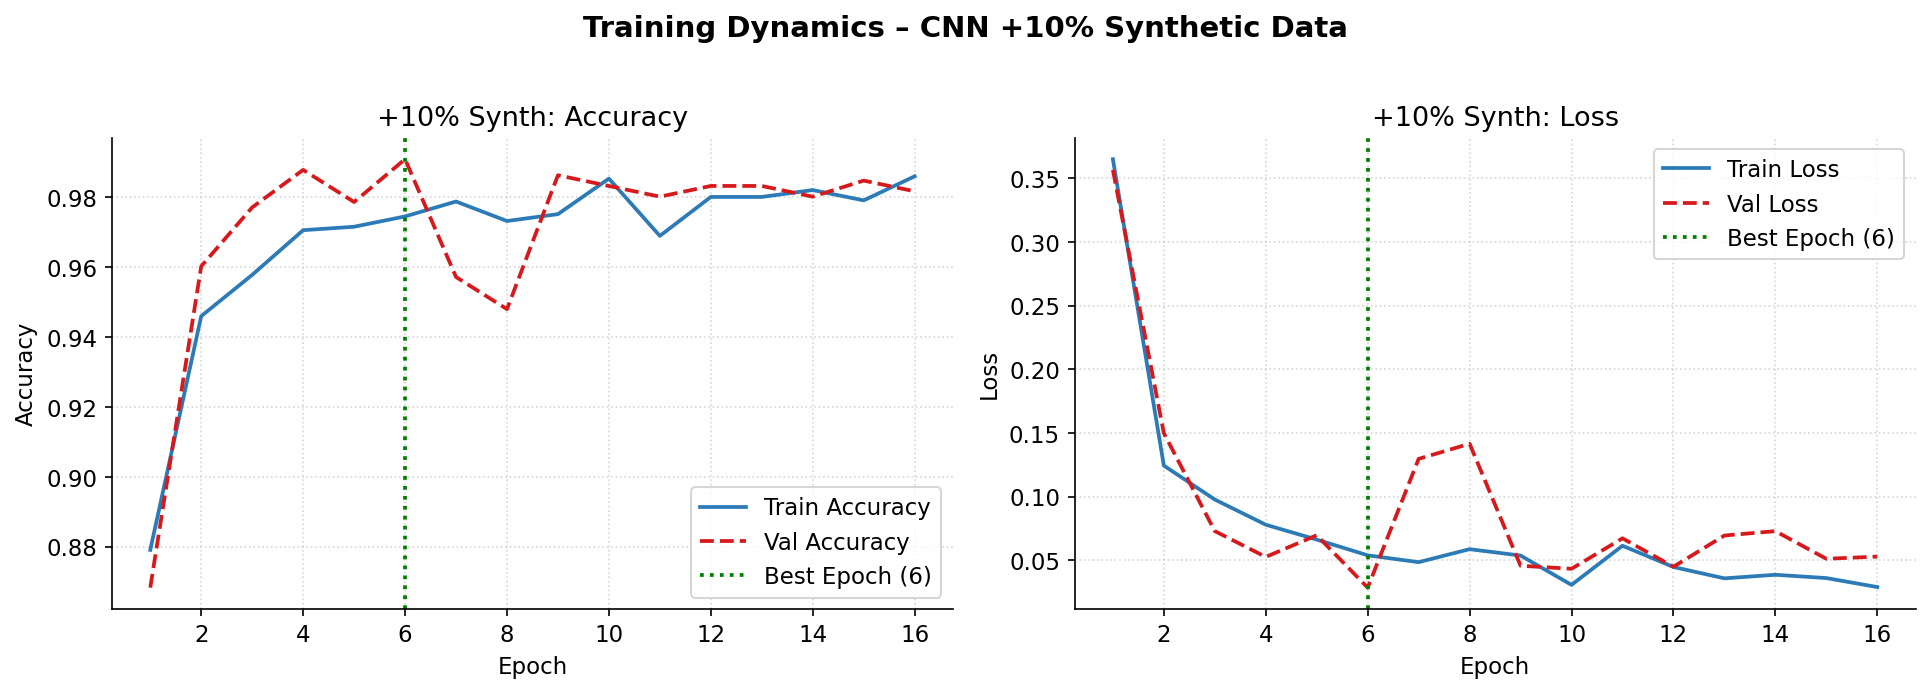

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_10pct_learning_curves.png


In [ ]:
# --- Step 5: Learning Curves ---
acc        = history.history['accuracy']
val_acc    = history.history['val_accuracy']
loss       = history.history['loss']
val_loss   = history.history['val_loss']
ep_range   = range(1, len(acc) + 1)
best_epoch = np.argmin(val_loss) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(ep_range, acc,     color=COLORS[0], label='Train Accuracy')
axes[0].plot(ep_range, val_acc, color=COLORS[1], linestyle='--', label='Val Accuracy')
axes[0].axvline(best_epoch, color='green', linestyle=':', label=f'Best Epoch ({best_epoch})')
axes[0].set_title('+10% Synth: Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(ep_range, loss,     color=COLORS[0], label='Train Loss')
axes[1].plot(ep_range, val_loss, color=COLORS[1], linestyle='--', label='Val Loss')
axes[1].axvline(best_epoch, color='green', linestyle=':', label=f'Best Epoch ({best_epoch})')
axes[1].set_title('+10% Synth: Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.suptitle('Training Dynamics – CNN +10% Synthetic Data',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_path = str(figures_path / 'fig_10pct_learning_curves.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")


## 6. Check model interfaces and inspect an example

Check the prediction shape and softmax sum, then display a randomly selected test image. These checks do not establish model quality, data independence, or prediction-set coverage.


  SMOKE TEST & SANITY CHECK – CNN +10%

[1/3] Smoke test (dummy input)...
      PASS – Output shape: (1, 3)

[2/3] Softmax sanity check...
      PASS – Probabilities sum to 1.000000

[3/3] Visual check on a real test image...


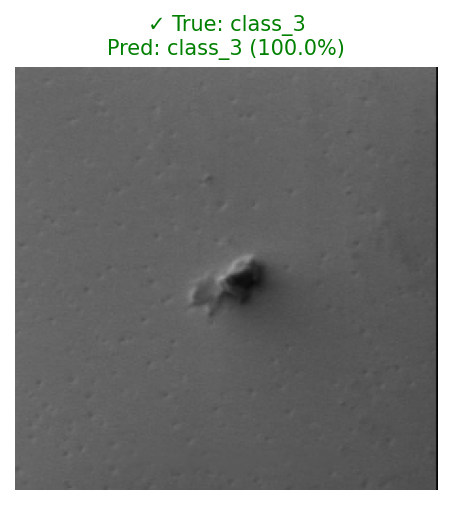


      True: class_3 | Pred: class_3 (100.0%) ✓

  ALL CHECKS PASSED


In [ ]:
# --- Step 6: Smoke Test & Sanity Check ---
import random
print("=" * 55)
print("  SMOKE TEST & SANITY CHECK – CNN +10%")
print("=" * 55)

# 1. Output shape
print("\n[1/3] Smoke test (dummy input)...")
dummy     = np.random.rand(1, 224, 224, 3).astype(np.float32)
pred_dummy = model.predict(dummy, verbose=0)
assert pred_dummy.shape == (1, num_classes), f"Wrong shape: {pred_dummy.shape}"
print(f"      PASS – Output shape: {pred_dummy.shape}")

# 2. Softmax sum
print("\n[2/3] Softmax sanity check...")
prob_sum = np.sum(pred_dummy)
assert 0.99 <= prob_sum <= 1.01
print(f"      PASS – Probabilities sum to {prob_sum:.6f}")

# 3. Visual check on a real test image
print("\n[3/3] Visual check on a real test image...")
idx             = random.randint(0, len(X_test) - 1)
real_path       = X_test[idx]
real_label_name = class_names[y_test[idx]]

img       = keras.utils.load_img(real_path, target_size=(224, 224))
img_arr   = keras.utils.img_to_array(img)
pred_prob = model.predict(np.expand_dims(img_arr, 0), verbose=0)
pred_name = class_names[np.argmax(pred_prob)]
confidence= np.max(pred_prob)
correct   = "✓" if pred_name == real_label_name else "✗"

plt.figure(figsize=(3.5, 3.5))
plt.imshow(img.resize((224, 224)))
plt.axis('off')
color = 'green' if pred_name == real_label_name else 'red'
plt.title(f"{correct} True: {real_label_name}\nPred: {pred_name} ({confidence:.1%})",
          color=color, fontsize=10)
plt.tight_layout()
plt.show()

print(f"\n      True: {real_label_name} | Pred: {pred_name} ({confidence:.1%}) {correct}")
print("\n" + "=" * 55)
print("  ALL CHECKS PASSED")
print("=" * 55)


## 7. Evaluate the selected checkpoint

Load the checkpoint and report class-wise classification metrics, Cohen's kappa, and a confusion matrix. Saved results are historical. The VAE training data overlap with the original images later held out for evaluation, so this is not a fully independent evaluation of the complete pipeline.


Loading best model...

--- Classification Report (+10% Synth) ---
              precision    recall  f1-score   support

     class_1       0.73      1.00      0.84         8
     class_3       1.00      1.00      1.00       602
     class_4       1.00      0.95      0.98        43

    accuracy                           0.99       653
   macro avg       0.91      0.98      0.94       653
weighted avg       1.00      0.99      0.99       653

--- Cohen's Kappa (+10% Synthetic) ---
κ = 0.9584


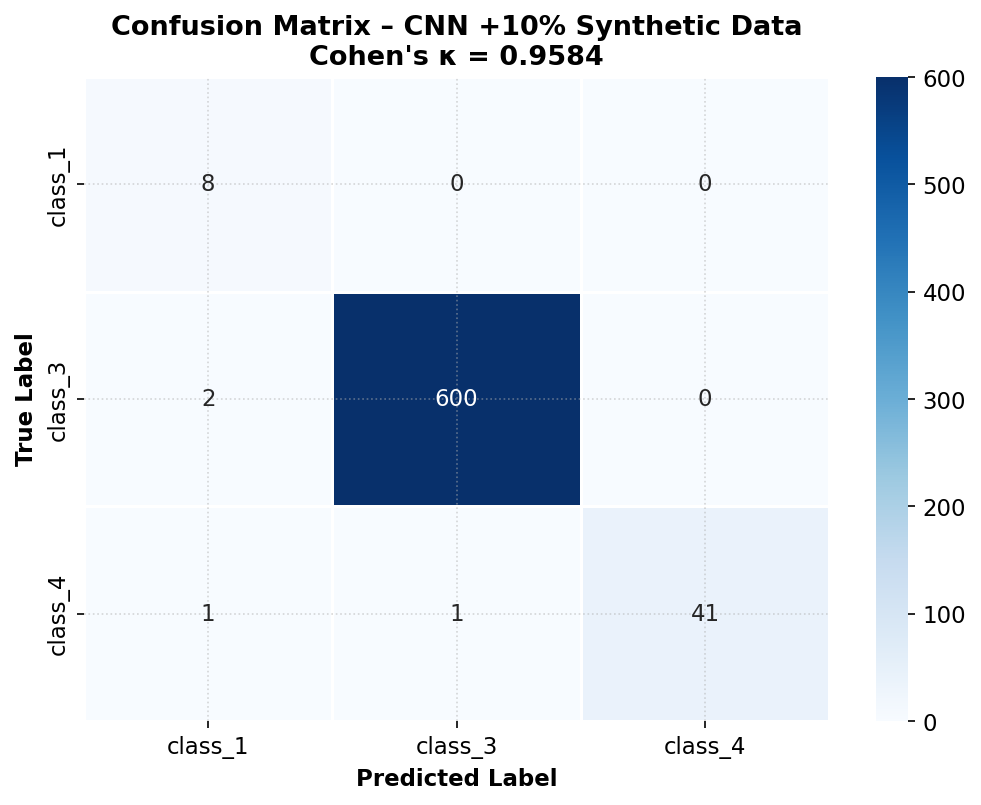

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_10pct_confusion_matrix.png


In [ ]:
# --- Step 7: Evaluation on Test Set ---
print("Loading best model...")
best_model = keras.models.load_model(checkpoint_path)

y_true_test  = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred_probs = best_model.predict(test_dataset, verbose=0)
y_pred       = np.argmax(y_pred_probs, axis=1)

print("\n--- Classification Report (+10% Synth) ---")
print(classification_report(y_true_test, y_pred, target_names=class_names))

# Cohen's Kappa
kappa = cohen_kappa_score(y_true_test, y_pred)
print(f"--- Cohen's Kappa (+10% Synthetic) ---")
print(f"κ = {kappa:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, ax=ax)
ax.set_ylabel('True Label', fontweight='bold')
ax.set_xlabel('Predicted Label', fontweight='bold')
ax.set_title(f'Confusion Matrix – CNN +10% Synthetic Data\nCohen\'s κ = {kappa:.4f}',
             fontweight='bold')
plt.tight_layout()
save_path = str(figures_path / 'fig_10pct_confusion_matrix.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")


## 8. Construct and evaluate prediction sets

Compute scores as one minus the predicted probability of the true class. The archived code uses NumPy's default interpolated 99th percentile without the finite-sample correction described in the thesis. The calibration subset was also used for model selection. Empirical coverage is reported at a nominal 99% target, not as verification of the standard finite-sample coverage guarantee.


In [ ]:
# Historical implementation: default interpolated quantile, without finite-sample correction.
# Construct prediction sets using the archived percentile-based calibration.
print("--- Conformal Prediction (+10% Experiment) ---")

X_cal_pool = np.concatenate([x for x, y in cal_dataset],  axis=0)
y_cal_pool = np.concatenate([y for x, y in cal_dataset],  axis=0)
X_test_pool= np.concatenate([x for x, y in test_dataset], axis=0)
y_test_pool= np.concatenate([y for x, y in test_dataset], axis=0)

y_probs_cal  = best_model.predict(X_cal_pool,  verbose=0)
y_probs_test = best_model.predict(X_test_pool, verbose=0)

# Non-conformity scores: 1 - P(true class)
scores_cal = 1 - y_probs_cal[np.arange(len(y_cal_pool)), y_cal_pool]

alpha       = 0.01
q_hat       = np.quantile(scores_cal, 1 - alpha)
threshold   = 1 - q_hat

prediction_sets = [np.where(p >= threshold)[0] for p in y_probs_test]

coverage     = np.mean([y_test_pool[i] in prediction_sets[i] for i in range(len(y_test_pool))])
avg_set_size = np.mean([len(s) for s in prediction_sets])

print(f"\n--- CP Results (+10% Synth, alpha={alpha}) ---")
print(f"  q_hat (99% confidence): {q_hat:.4f}")
print(f"  Empirical Coverage:     {coverage:.2%}  (target: ≥{(1-alpha):.0%})")
print(f"  Avg. Prediction Set Size: {avg_set_size:.3f}")

results_10percent = {
    "model": "+10% Synth", "coverage": coverage,
    "avg_set_size": avg_set_size, "q_hat": q_hat
}


--- Conformal Prediction (+10% Experiment) ---

--- CP Results (+10% Synth, alpha=0.01) ---
  q_hat (99% confidence): 0.3406
  Empirical Coverage:     98.77%  (target: ≥99%)
  Avg. Prediction Set Size: 0.994


## 9. Plot the calibration-score threshold

Display sorted calibration scores and the archived threshold. Original plot labels and output text are retained for traceability. References to 99% confidence must not be interpreted as a per-image correctness guarantee. At inference, each candidate label has a score; the true-label score is unavailable without ground truth.


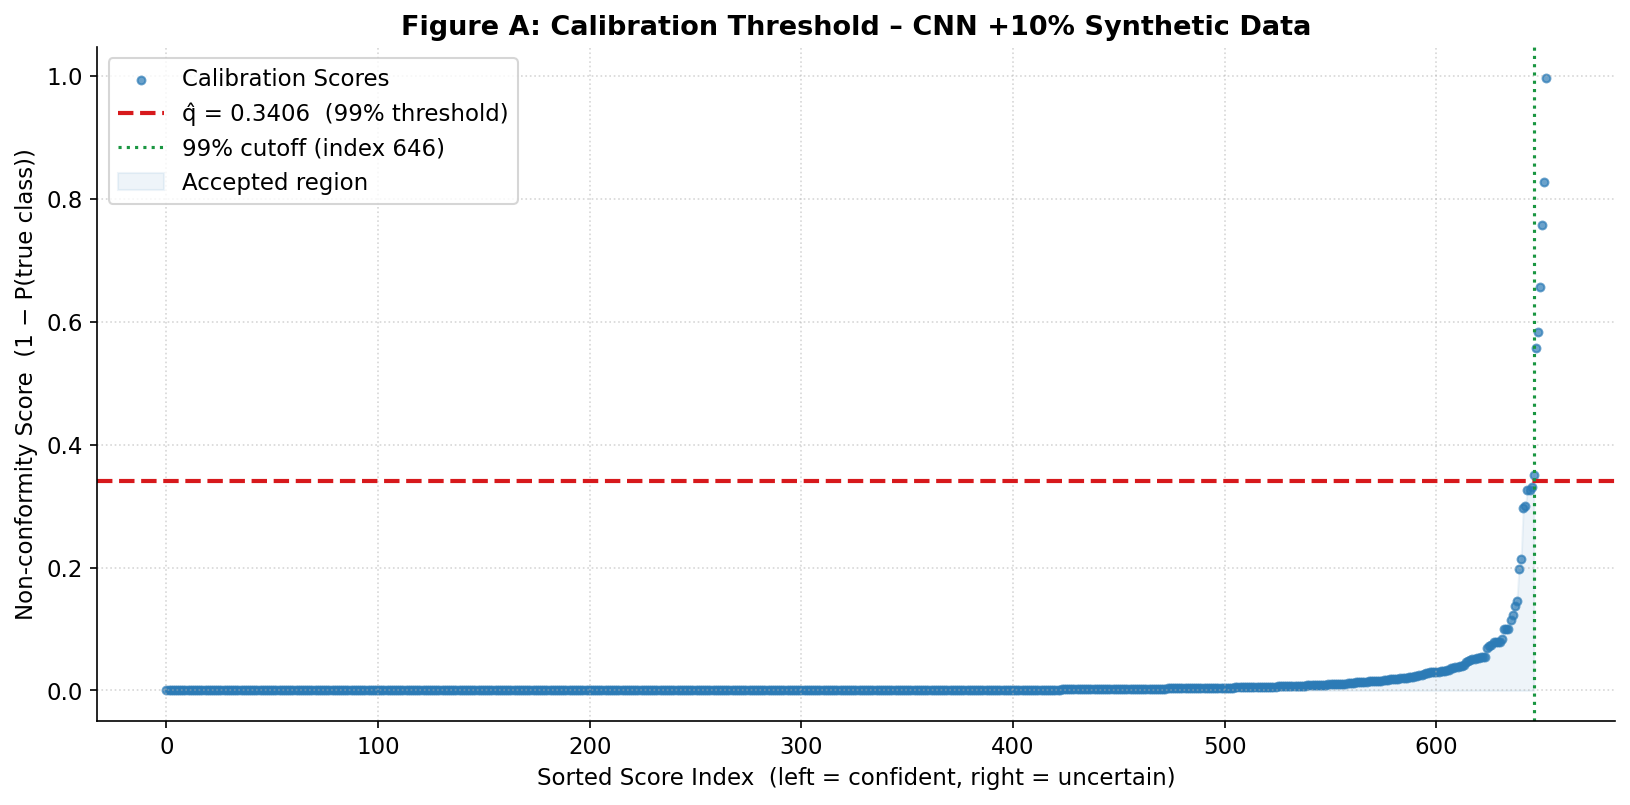

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_10pct_calibration_threshold.png
Interpretation: All new images with score ≤ 0.3406 are accepted at 99% confidence.


In [ ]:
# --- Step 9: Calibration Threshold Plot (Figure A) ---
sorted_scores = np.sort(scores_cal)
score_idx     = np.arange(len(sorted_scores))
cutoff_idx    = int(len(sorted_scores) * (1 - alpha))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(score_idx, sorted_scores, s=14, color=COLORS[0], alpha=0.7,
           label='Calibration Scores')
ax.axhline(q_hat, color=COLORS[1], linestyle='--', linewidth=2,
           label=f'q̂ = {q_hat:.4f}  (99% threshold)')
ax.axvline(cutoff_idx, color=COLORS[2], linestyle=':', linewidth=1.5,
           label=f'99% cutoff (index {cutoff_idx})')
ax.fill_between(score_idx, 0, sorted_scores,
                where=(score_idx <= cutoff_idx),
                color=COLORS[0], alpha=0.08, label='Accepted region')
ax.set_title('Figure A: Calibration Threshold – CNN +10% Synthetic Data',
             fontweight='bold')
ax.set_xlabel('Sorted Score Index  (left = confident, right = uncertain)')
ax.set_ylabel('Non-conformity Score  (1 − P(true class))')
ax.legend()
plt.tight_layout()
save_path = str(figures_path / 'fig_10pct_calibration_threshold.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")
print(f"Interpretation: All new images with score ≤ {q_hat:.4f} are accepted at 99% confidence.")


## 10. Inspect class-wise coverage and set size

Report empirical coverage and mean prediction-set size by true class. These are descriptive results, not class-conditional guarantees. The stored test report contains eight Class 1 examples. Prediction sets may be empty; average set size should be interpreted together with coverage.


--- Per-Class CP Analysis (+10% Synth) ---

  class_1 (n=   8):  Coverage=87.50%  |  Avg Set Size=0.875
  class_3 (n= 602):  Coverage=99.17%  |  Avg Set Size=0.995
  class_4 (n=  43):  Coverage=95.35%  |  Avg Set Size=1.000


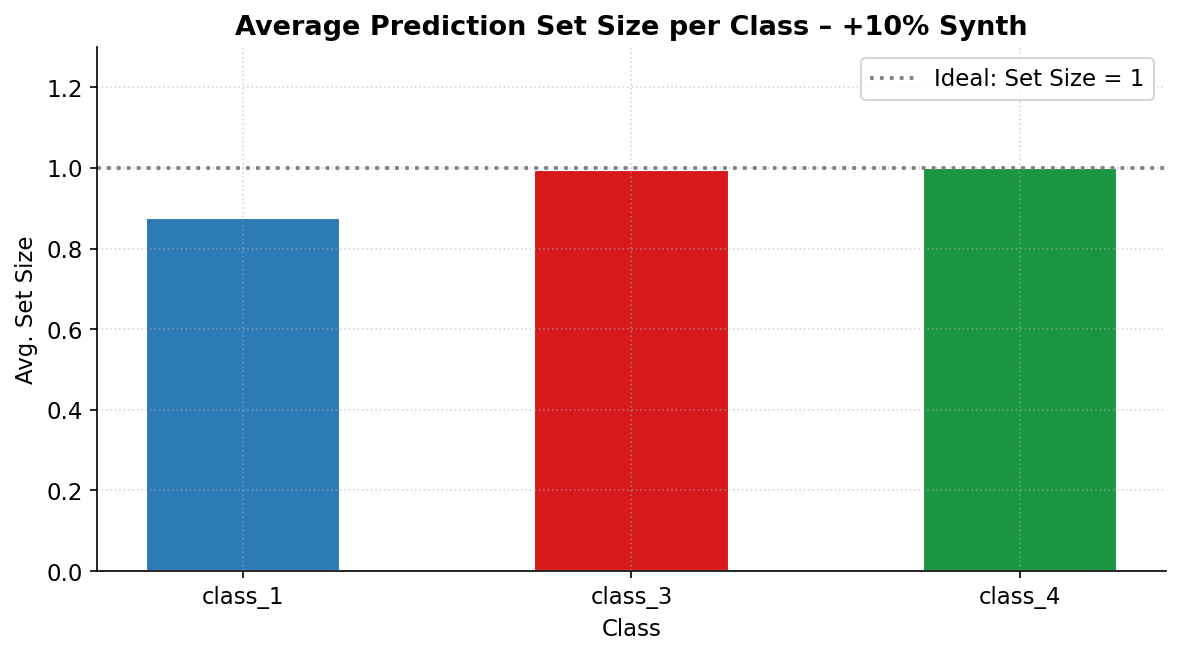

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_10pct_setsize_per_class.png


In [ ]:
# --- Step 10: Per-Class Conformal Prediction Analysis ---
print("--- Per-Class CP Analysis (+10% Synth) ---\n")

for class_idx, class_name in enumerate(class_names):
    mask          = y_test_pool == class_idx
    sets_for_cls  = [prediction_sets[i] for i in range(len(y_test_pool)) if mask[i]]
    true_labels   = y_test_pool[mask]

    if len(true_labels) == 0:
        continue

    cov  = np.mean([true_labels[i] in sets_for_cls[i] for i in range(len(true_labels))])
    avg  = np.mean([len(s) for s in sets_for_cls])
    n    = len(true_labels)
    print(f"  {class_name} (n={n:4d}):  Coverage={cov:.2%}  |  Avg Set Size={avg:.3f}")

# Visualize set size distribution
set_sizes = [len(s) for s in prediction_sets]
labels_map = {0: 'class_1', 1: 'class_3', 2: 'class_4'}
sizes_by_class = {name: [] for name in class_names}
for i, s in enumerate(prediction_sets):
    sizes_by_class[class_names[y_test_pool[i]]].append(len(s))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(class_names,
       [np.mean(sizes_by_class[c]) for c in class_names],
       color=COLORS[:len(class_names)], width=0.5, edgecolor='white')
ax.axhline(1.0, color='gray', linestyle=':', label='Ideal: Set Size = 1')
ax.set_title('Average Prediction Set Size per Class – +10% Synth', fontweight='bold')
ax.set_ylabel('Avg. Set Size')
ax.set_xlabel('Class')
ax.set_ylim(0, max([np.mean(sizes_by_class[c]) for c in class_names]) + 0.3)
ax.legend()
plt.tight_layout()
save_path = str(figures_path / 'fig_10pct_setsize_per_class.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")
